## 1. Exploratory Data Analysis

In [7]:
import pandas as pd

df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features.csv")
print(df.shape)
df.head()

(98, 15)


,video_id,total_frames,face_detection_rate,pose_detection_rate,eye_openness_mean,eye_openness_std,blink_rate,mouth_open_mean,mouth_open_std,head_yaw_mean,head_yaw_std,shoulder_diff_mean,shoulder_diff_std,wrist_l_motion,wrist_r_motion
0,ashish chanchlani vines_6w_Wy2Sb82w,294,0.129252,0.295918,0.012698,0.003580,0.095238,0.010558,0.009647,0.034592,0.078391,0.027257,0.027486,0.150067,0.179434
1,ashish chanchlani vines_HjzIiSjqiC0,139,0.100719,0.316547,0.009526,0.003338,0.100719,0.004906,0.003718,0.203878,0.071898,0.021131,0.028993,0.105642,0.126042
2,ashish chanchlani vines_hm7xnyNypC0,358,0.505587,0.916201,0.007603,0.003723,0.505587,0.007471,0.005965,-0.034243,0.165393,0.016103,0.016908,0.112382,0.117224
3,ashish chanchlani vines_kvC71IVwGKc,239,0.489540,0.895397,0.007045,0.004755,0.451883,0.012869,0.006351,0.010307,0.129104,0.035625,0.029583,0.175507,0.148968
4,ashish chanchlani vines_n9wjzlXPHxw,97,0.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.023734,0.021082,0.059387,0.055776


In [8]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BaseOptions = python.BaseOptions
VisionRunningMode = vision.RunningMode
face_model_path = "face_landmarker.task"

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   video_id             98 non-null     object 
 1   total_frames         98 non-null     int64  
 2   face_detection_rate  98 non-null     float64
 3   pose_detection_rate  98 non-null     float64
 4   eye_openness_mean    57 non-null     float64
 5   eye_openness_std     56 non-null     float64
 6   blink_rate           98 non-null     float64
 7   mouth_open_mean      57 non-null     float64
 8   mouth_open_std       56 non-null     float64
 9   head_yaw_mean        57 non-null     float64
 10  head_yaw_std         56 non-null     float64
 11  shoulder_diff_mean   93 non-null     float64
 12  shoulder_diff_std    91 non-null     float64
 13  wrist_l_motion       98 non-null     float64
 14  wrist_r_motion       98 non-null     float64
dtypes: float64(13), int64(1), object(1)
memory

In [10]:
df.describe()

,total_frames,face_detection_rate,pose_detection_rate,eye_openness_mean,eye_openness_std,blink_rate,mouth_open_mean,mouth_open_std,head_yaw_mean,head_yaw_std,shoulder_diff_mean,shoulder_diff_std,wrist_l_motion,wrist_r_motion
count,98.000000,98.000000,98.000000,57.000000,56.000000,98.000000,57.000000,56.000000,57.000000,56.000000,93.000000,91.000000,98.000000,98.000000
mean,139.306122,0.303314,0.610725,0.013188,0.005121,0.195395,0.010330,0.008410,-0.025433,0.083272,0.035174,0.029301,0.137612,0.138021
std,89.863976,0.351023,0.351349,0.009622,0.003884,0.263968,0.006430,0.005199,0.160356,0.047697,0.038738,0.029714,0.117682,0.129452
min,30.000000,0.000000,0.000000,0.001333,0.000738,0.000000,0.000249,0.000285,-0.876137,0.003618,0.001904,0.001115,0.000000,0.000000
25%,72.000000,0.000000,0.298299,0.007045,0.003031,0.000000,0.005779,0.005428,-0.050524,0.051302,0.012801,0.011428,0.065278,0.058838
50%,109.500000,0.114986,0.727019,0.010916,0.004196,0.050720,0.009396,0.007647,0.000922,0.074932,0.023734,0.019869,0.112079,0.114785
75%,186.750000,0.530734,0.948977,0.017356,0.005719,0.340686,0.013308,0.009194,0.034559,0.116769,0.039347,0.032364,0.180312,0.168376
max,366.000000,1.000000,1.000000,0.062857,0.022728,1.000000,0.027168,0.024679,0.279907,0.194487,0.279593,0.178050,0.849254,0.839491


In [11]:
df.isnull().sum()

video_id                0
total_frames            0
face_detection_rate     0
pose_detection_rate     0
eye_openness_mean      41
eye_openness_std       42
blink_rate              0
mouth_open_mean        41
mouth_open_std         42
head_yaw_mean          41
head_yaw_std           42
shoulder_diff_mean      5
shoulder_diff_std       7
wrist_l_motion          0
wrist_r_motion          0
dtype: int64

In [12]:
df["source"] = df["video_id"].str.extract(r'^([a-zA-Z_ ]+?)_')
df.groupby("source")["face_detection_rate"].agg(['mean', 'count'])

,mean,count
source,,
Dushyant kukreja,0.374941,9
Flying Beast,0.741388,2
Mamaearth India,0.491535,9
SUGAR Cosmetics,0.521077,10
Technical Guruji,0.245059,1
Trakin Tech English,0.374314,4
WOW Skin Science India,0.322383,7
ashish chanchlani vines,0.287851,6
mCaffeine,0.487146,9


In [20]:
df.groupby("source")[["face_detection_rate", "pose_detection_rate"]].agg(['mean', 'count'])

face_detection_rate       pose_detection_rate      
                                       mean count                mean count
source                                                                     
Dushyant kukreja                   0.374941     9            0.953804     9
Flying Beast                       0.741388     2            0.938359     2
Mamaearth India                    0.491535     9            0.626881     9
SUGAR Cosmetics                    0.521077    10            0.643114    10
Technical Guruji                   0.245059     1            0.683794     1
Trakin Tech English                0.374314     4            0.481729     4
WOW Skin Science India             0.322383     7            0.416835     7
ashish chanchlani vines            0.287851     6            0.695845     6
mCaffeine                          0.487146     9            0.705854     9
pixabay                            0.122366    35            0.495369    35
wearecult                          0.000000     4            0.510675     4

In [21]:
df[["wrist_l_motion", "wrist_r_motion", "shoulder_diff_mean", "blink_rate"]].describe()

,wrist_l_motion,wrist_r_motion,shoulder_diff_mean,blink_rate
count,98.000000,98.000000,93.000000,98.000000
mean,0.137612,0.138021,0.035174,0.195395
std,0.117682,0.129452,0.038738,0.263968
min,0.000000,0.000000,0.001904,0.000000
25%,0.065278,0.058838,0.012801,0.000000
50%,0.112079,0.114785,0.023734,0.050720
75%,0.180312,0.168376,0.039347,0.340686
max,0.849254,0.839491,0.279593,1.000000


## 2. Bug Investigation: Blink Rate Anomaly

In [22]:
# Check videos with unusually high blink_rate (>0.8) - likely a detection issue, not real blinking
# Also show face_detection_rate and total_frames for context
df[df["blink_rate"] > 0.8][["video_id", "blink_rate", "face_detection_rate", "total_frames"]]

,video_id,blink_rate,face_detection_rate,total_frames
7,Dushyant kukreja_7GfDz177muA,0.825301,0.843373,166
11,Dushyant kukreja_i2xtm_rlCeM,1.000000,1.000000,80
16,Flying Beast_PCAJH2axsrY,0.959839,0.959839,249
95,WOW Skin Science India_NhxOGhwHcMM,0.813333,0.893333,75


In [23]:
# Load one flagged video's raw landmarks and check eye_openness values directly
import pickle

with open("D:/UGC_Project/pilot_features/raw_landmarks/Dushyant kukreja_i2xtm_rlCeM.pkl", "rb") as f:
    landmarks = pickle.load(f)

# print eye openness for first 10 frames with face detected
for i, frame_data in enumerate(landmarks[:10]):
    if frame_data["face"] is not None:
        lm = frame_data["face"]
        left_eye = abs(lm[159][1] - lm[145][1])
        right_eye = abs(lm[386][1] - lm[374][1])
        print(f"Frame {i}: eye_openness = {(left_eye+right_eye)/2:.4f}")

Frame 0: eye_openness = 0.0056
Frame 1: eye_openness = 0.0075
Frame 2: eye_openness = 0.0087
Frame 3: eye_openness = 0.0084
Frame 4: eye_openness = 0.0083
Frame 5: eye_openness = 0.0083
Frame 6: eye_openness = 0.0099
Frame 7: eye_openness = 0.0091
Frame 8: eye_openness = 0.0084
Frame 9: eye_openness = 0.0088


In [24]:
BLINK_THRESHOLD = 0.06   # as a ratio of face width, not absolute pixel distance

In [25]:
# Normalize eye_openness relative to face width (distance between cheeks) instead of raw absolute value
# This makes the measurement consistent regardless of how close/far the face is from camera

def get_frame_features_v2(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

    face_result = face_landmarker.detect(mp_image)
    pose_result = pose_landmarker.detect(mp_image)

    features = {
        "face_detected": 0, "pose_detected": 0,
        "eye_openness": None, "mouth_open": None, "head_yaw": None,
        "shoulder_diff": None, "wrist_l_x": None, "wrist_l_y": None,
        "wrist_r_x": None, "wrist_r_y": None,
    }
    face_landmarks_raw = None
    pose_landmarks_raw = None

    if face_result.face_landmarks:
        lm = face_result.face_landmarks[0]
        features["face_detected"] = 1

        # face width = distance between cheeks - used to normalize other measurements
        face_width = abs(lm[234].x - lm[454].x)

        left_eye = abs(lm[159].y - lm[145].y)
        right_eye = abs(lm[386].y - lm[374].y)
        raw_eye_openness = (left_eye + right_eye) / 2

        # normalize: eye openness as a ratio of face width, not raw pixel-space value
        features["eye_openness"] = raw_eye_openness / face_width if face_width > 0 else None
        features["mouth_open"] = abs(lm[13].y - lm[14].y) / face_width if face_width > 0 else None
        features["head_yaw"] = (abs(lm[1].x - lm[234].x) - abs(lm[1].x - lm[454].x)) / face_width if face_width > 0 else None
        face_landmarks_raw = [(p.x, p.y, p.z) for p in lm]

    if pose_result.pose_landmarks:
        lm = pose_result.pose_landmarks[0]
        features["pose_detected"] = 1
        features["shoulder_diff"] = abs(lm[11].y - lm[12].y)
        features["wrist_l_x"], features["wrist_l_y"] = lm[15].x, lm[15].y
        features["wrist_r_x"], features["wrist_r_y"] = lm[16].x, lm[16].y
        pose_landmarks_raw = [(p.x, p.y, p.z) for p in lm]

    return features, face_landmarks_raw, pose_landmarks_raw

In [29]:
pose_model_path = "pose_landmarker.task"

pose_landmarker = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=pose_model_path),
        running_mode=VisionRunningMode.IMAGE))

print("pose_landmarker created:", pose_landmarker is not None)


# re-check eye_openness with the normalized version on the same video's frames
test_id = "Dushyant kukreja_i2xtm_rlCeM"
frames_dir = os.path.join(PILOT_FRAMES_DIR, test_id)
frame_files = sorted(os.listdir(frames_dir))

for fname in frame_files[:10]:
    frame = cv2.imread(os.path.join(frames_dir, fname))
    feats, _, _ = get_frame_features_v2(frame)
    print(f"{fname}: eye_openness = {feats['eye_openness']}")


pose_landmarker created: True
frame_0000.jpg: eye_openness = 0.026208198201931963
frame_0001.jpg: eye_openness = 0.035567436934887564
frame_0002.jpg: eye_openness = 0.03794455600934158
frame_0003.jpg: eye_openness = 0.03636772946508656
frame_0004.jpg: eye_openness = 0.03594922448254839
frame_0005.jpg: eye_openness = 0.03646101628495672
frame_0006.jpg: eye_openness = 0.03394067269897172
frame_0007.jpg: eye_openness = 0.0317574714776072
frame_0008.jpg: eye_openness = 0.030326855535732344
frame_0009.jpg: eye_openness = 0.03141926778959122


In [30]:
# Collect normalized eye_openness values across a few different videos to see the real distribution
import numpy as np

all_values = []
sample_videos = df[df["face_detection_rate"] > 0.5]["video_id"].head(5).tolist()

for vid in sample_videos:
    frames_dir = os.path.join(PILOT_FRAMES_DIR, vid)
    frame_files = sorted(os.listdir(frames_dir))
    for fname in frame_files:
        frame = cv2.imread(os.path.join(frames_dir, fname))
        feats, _, _ = get_frame_features_v2(frame)
        if feats["eye_openness"] is not None:
            all_values.append(feats["eye_openness"])

all_values = np.array(all_values)
print(f"Total samples: {len(all_values)}")
print(f"Min: {all_values.min():.4f}, Max: {all_values.max():.4f}")
print(f"25th percentile: {np.percentile(all_values, 25):.4f}")
print(f"50th percentile (median): {np.percentile(all_values, 50):.4f}")
print(f"10th percentile: {np.percentile(all_values, 10):.4f}")

Total samples: 698
Min: 0.0004, Max: 0.0565
25th percentile: 0.0264
50th percentile (median): 0.0332
10th percentile: 0.0155


In [34]:
BLINK_THRESHOLD = 0.0155   # recalibrated from real data (10th percentile)
from tqdm import tqdm
def process_video_v2(video_id, frames_dir):
    frame_files = sorted(os.listdir(frames_dir))
    per_frame_features = []
    landmark_sequence = []

    for fname in frame_files:
        frame_path = os.path.join(frames_dir, fname)
        frame = cv2.imread(frame_path)
        if frame is None:
            continue
        feats, face_lm, pose_lm = get_frame_features_v2(frame)
        per_frame_features.append(feats)
        landmark_sequence.append({"face": face_lm, "pose": pose_lm})

    if not per_frame_features:
        return None

    df = pd.DataFrame(per_frame_features)
    total_frames = len(df)

    row = {
        "video_id": video_id,
        "total_frames": total_frames,
        "face_detection_rate": df["face_detected"].mean(),
        "pose_detection_rate": df["pose_detected"].mean(),
        "eye_openness_mean": df["eye_openness"].mean(),
        "eye_openness_std": df["eye_openness"].std(),
        "blink_rate": (df["eye_openness"] < BLINK_THRESHOLD).sum() / max(total_frames, 1),
        "mouth_open_mean": df["mouth_open"].mean(),
        "mouth_open_std": df["mouth_open"].std(),
        "head_yaw_mean": df["head_yaw"].mean(),
        "head_yaw_std": df["head_yaw"].std(),
        "shoulder_diff_mean": df["shoulder_diff"].mean(),
        "shoulder_diff_std": df["shoulder_diff"].std(),
    }

    wrist_l = df[["wrist_l_x", "wrist_l_y"]].dropna().values
    wrist_r = df[["wrist_r_x", "wrist_r_y"]].dropna().values
    row["wrist_l_motion"] = np.mean(np.linalg.norm(np.diff(wrist_l, axis=0), axis=1)) if len(wrist_l) > 1 else 0
    row["wrist_r_motion"] = np.mean(np.linalg.norm(np.diff(wrist_r, axis=0), axis=1)) if len(wrist_r) > 1 else 0

    with open(os.path.join(LANDMARKS_DIR, f"{video_id}_v2.pkl"), "wb") as f:
        pickle.dump(landmark_sequence, f)

    return row

In [36]:
LANDMARKS_DIR = "D:/UGC_Project/pilot_features/raw_landmarks"
video_folders = os.listdir(PILOT_FRAMES_DIR)
print(f"Total videos to process: {len(video_folders)}")

results = []
for video_id in tqdm(video_folders, desc="Extracting features (v2)"):
    frames_dir = os.path.join(PILOT_FRAMES_DIR, video_id)
    row = process_video_v2(video_id, frames_dir)
    if row is not None:
        results.append(row)

feature_df = pd.DataFrame(results)
feature_df.to_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_v2.csv", index=False)

print(f"\nProcessed videos: {len(feature_df)}")
print(f"Average blink_rate: {feature_df['blink_rate'].mean():.3f}")
print(f"Videos with blink_rate > 0.8: {(feature_df['blink_rate'] > 0.8).sum()}")

Total videos to process: 100


Extracting features (v2): 100%|██████████████████████████████████████████████████████| 100/100 [49:28<00:00, 29.69s/it]


Processed videos: 98
Average blink_rate: 0.042
Videos with blink_rate > 0.8: 0


In [37]:
# Load the corrected (v2) statistical features
df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_v2.csv")

# Face-based columns that have NaN when face wasn't detected in a video
face_feature_cols = [
    "eye_openness_mean", "eye_openness_std",
    "mouth_open_mean", "mouth_open_std",
    "head_yaw_mean", "head_yaw_std"
]

# Add a flag column: 1 if the video had usable face data, 0 if not
# This lets the model learn "no face data" as its own signal, instead of hiding it
df["has_face_data"] = (df["face_detection_rate"] > 0.1).astype(int)

# Fill missing face-based values with the column mean
# (keeps the model from breaking on NaN, without distorting the data too much)
df[face_feature_cols] = df[face_feature_cols].fillna(df[face_feature_cols].mean())

# Pose-based columns also had a few missing values (5-7 videos) - same fix
pose_feature_cols = ["shoulder_diff_mean", "shoulder_diff_std"]
df[pose_feature_cols] = df[pose_feature_cols].fillna(df[pose_feature_cols].mean())

# Confirm no more missing values remain
print(df.isnull().sum())

# Save the cleaned, training-ready version
df.to_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_final.csv", index=False)
print("\nSaved cleaned dataset as pilot_statistical_features_final.csv")


video_id               0
total_frames           0
face_detection_rate    0
pose_detection_rate    0
eye_openness_mean      0
eye_openness_std       0
blink_rate             0
mouth_open_mean        0
mouth_open_std         0
head_yaw_mean          0
head_yaw_std           0
shoulder_diff_mean     0
shoulder_diff_std      0
wrist_l_motion         0
wrist_r_motion         0
has_face_data          0
dtype: int64

Saved cleaned dataset as pilot_statistical_features_final.csv


## 3. Label Cleaning (Label Studio Export)

In [38]:
import pandas as pd
import re
import json

# Load the raw Label Studio export
labels_df = pd.read_csv("AI-ugcLabelStudio100.csv")

# Label Studio stores the rating as a string like: [{"rating":3}]
# This function parses that string and pulls out just the number (3)
def extract_rating(val):
    try:
        return json.loads(val.replace("'", '"'))[0]["rating"]
    except Exception:
        return None  # if parsing fails for any row, mark it None so we can spot it later

# Apply the rating extraction to every row, replacing the messy JSON string with a clean number
labels_df["realism_score"] = labels_df["realism_score"].apply(extract_rating)

# The "video" column looks like: /data/upload/9/9d159309-SUGAR_Cosmetics_9yXM-4Bqyy0.mp4
# We need just: SUGAR_Cosmetics_9yXM-4Bqyy0  (to match your features CSV's video_id)
def extract_video_id(path):
    filename = path.split("/")[-1]                      # keep only the last part after the final

In [39]:
features_df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_final.csv")

## 4. Label Cleaning — Retry (Path Fix)

In [44]:
import pandas as pd
import re
import json
import os

# Make sure the labels folder exists before saving
os.makedirs("D:/UGC_Project/labels", exist_ok=True)

# Load the raw Label Studio export (update path to wherever you actually have this CSV)
labels_df = pd.read_csv("AI-ugcLabelStudio100.csv")

# Extract numeric rating from the JSON-like string, e.g. [{"rating":3}] -> 3
def extract_rating(val):
    try:
        return json.loads(val.replace("'", '"'))[0]["rating"]
    except Exception:
        return None

labels_df["realism_score"] = labels_df["realism_score"].apply(extract_rating)

# Extract clean video_id from the upload path
def extract_video_id(path):
    filename = path.split("/")[-1]
    filename = re.sub(r"^[0-9a-f]{8}-", "", filename)
    filename = filename.rsplit(".", 1)[0]
    return filename

labels_df["video_id"] = labels_df["video"].apply(extract_video_id)

labels_df = labels_df[["video_id", "realism_score"]]

labels_df.to_csv("D:/UGC_Project/labels/pilot_labels_clean.csv", index=False)

print(labels_df.head())
print(f"\nTotal labeled: {len(labels_df)}")
print(f"\nRating distribution:\n{labels_df['realism_score'].value_counts().sort_index()}")

# Confirm it actually saved
print(f"\nFile exists now: {os.path.exists('D:/UGC_Project/labels/pilot_labels_clean.csv')}")

                              video_id  realism_score
0  ashish_chanchlani_vines_6w_Wy2Sb82w              3
1  ashish_chanchlani_vines_HjzIiSjqiC0              2
2  ashish_chanchlani_vines_hm7xnyNypC0              3
3  ashish_chanchlani_vines_kvC71IVwGKc              4
4  ashish_chanchlani_vines_n9wjzlXPHxw              3

Total labeled: 100

Rating distribution:
realism_score
1    11
2    20
3    18
4    30
5    21
Name: count, dtype: int64

File exists now: True


In [45]:
import pandas as pd

features_df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_final.csv")
labels_df = pd.read_csv("D:/UGC_Project/labels/pilot_labels_clean.csv")

print(f"Features rows: {len(features_df)}")
print(f"Labels rows: {len(labels_df)}")

merged_df = pd.merge(features_df, labels_df, on="video_id", how="inner")

print(f"\nMerged rows: {len(merged_df)}")

unmatched_labels = set(labels_df["video_id"]) - set(merged_df["video_id"])
unmatched_features = set(features_df["video_id"]) - set(merged_df["video_id"])

print(f"\nLabeled videos with no matching features: {len(unmatched_labels)}")
if unmatched_labels:
    print(unmatched_labels)

print(f"\nFeature rows with no matching label: {len(unmatched_features)}")
if unmatched_features:
    print(unmatched_features)

merged_df.to_csv("D:/UGC_Project/pilot_features/pilot_train_ready.csv", index=False)
print(f"\nSaved: D:/UGC_Project/pilot_features/pilot_train_ready.csv")
print(f"Final shape: {merged_df.shape}")

Features rows: 98
Labels rows: 100

Merged rows: 46

Labeled videos with no matching features: 54
{'SUGAR_Cosmetics_9yXM-4Bqyy0', 'ashish_chanchlani_vines_hm7xnyNypC0', 'SUGAR_Cosmetics_HxtoJ7C3XLk', 'Dushyant_kukreja_i2xtm_rlCeM', 'Technical_Guruji_Me4iRRV9LS0', 'Dushyant_kukreja_dAWuvhklSFs', 'Dushyant_kukreja_drm6bfK3kHc', 'Mamaearth_India_i1PXRwMdypA', 'WOW_Skin_Science_India_NhxOGhwHcMM', 'WOW_Skin_Science_India_Xq7AHh6Qm6M', 'ashish_chanchlani_vines_n9wjzlXPHxw', 'Mamaearth_India_Rg0wHN6Yclo', 'ashish_chanchlani_vines_t1TstauVuhE', 'Mamaearth_India_4NxZ5xPshrQ', 'Flying_Beast_10OXfj6lAhI', 'Physics_Wallah_-_Alakh_Pandey_WkDi6CDcQCo', 'WOW_Skin_Science_India_314allEv6I4', 'indian_men_advertising_page1_58', 'Mamaearth_India_1z984PLZhhQ', 'Dushyant_kukreja_FyBjmJvbe_0', 'Dushyant_kukreja_7GfDz177muA', 'WOW_Skin_Science_India_2OtSxNLpiTo', 'Mamaearth_India_qtBVsov2qEo', 'indian_women_advertising_page1_17', 'Mamaearth_India_OFTbe9FJgXs', 'SUGAR_Cosmetics_UDtT4bAOMqY', 'african_women_p

## 5. Feature–Label Merge — Attempt 1

In [47]:
import pandas as pd
import urllib.parse

features_df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_final.csv")
labels_df = pd.read_csv("D:/UGC_Project/labels/pilot_labels_clean.csv")

# Fix 1: normalize features_df video_id — replace spaces with underscores
features_df["video_id"] = features_df["video_id"].str.replace(" ", "_", regex=False)

# Fix 2: decode URL-encoded characters in labels_df video_id
labels_df["video_id"] = labels_df["video_id"].apply(urllib.parse.unquote)

print("Features rows:", len(features_df))
print("Labels rows:", len(labels_df))

merged_df = pd.merge(features_df, labels_df, on="video_id", how="inner")
print("Merged rows:", len(merged_df))

unmatched_labels = set(labels_df["video_id"]) - set(merged_df["video_id"])
unmatched_features = set(features_df["video_id"]) - set(merged_df["video_id"])

print("Labeled videos with no matching features:", len(unmatched_labels))
if unmatched_labels:
    print(unmatched_labels)

print("Feature rows with no matching label:", len(unmatched_features))
if unmatched_features:
    print(unmatched_features)

out_path = "D:/UGC_Project/pilot_features/pilot_train_ready.csv"
merged_df.to_csv(out_path, index=False)
print("Saved:", out_path)
print("Final shape:", merged_df.shape)

Features rows: 98
Labels rows: 100
Merged rows: 94
Labeled videos with no matching features: 6
{'african_men_page1_28', 'जश_Talks_Q6vSWnpkQ1U', 'जश_Talks_KbjY8BMi5AY', 'indian_men_advertising_page1_58', 'indian_women_advertising_page1_17', 'african_women_page1_30'}
Feature rows with no matching label: 4
{'wearecult_KtJZGq9Kuf4', 'WOW_Skin_Science_India_2znxEnFq8Ms', 'WOW_Skin_Science_India_EjSQpf_tZ3g', 'pixabay_global_218506'}
Saved: D:/UGC_Project/pilot_features/pilot_train_ready.csv
Final shape: (94, 17)


## 6. Feature–Label Merge — Fixed

Shape: (94, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   video_id             94 non-null     object 
 1   total_frames         94 non-null     int64  
 2   face_detection_rate  94 non-null     float64
 3   pose_detection_rate  94 non-null     float64
 4   eye_openness_mean    94 non-null     float64
 5   eye_openness_std     94 non-null     float64
 6   blink_rate           94 non-null     float64
 7   mouth_open_mean      94 non-null     float64
 8   mouth_open_std       94 non-null     float64
 9   head_yaw_mean        94 non-null     float64
 10  head_yaw_std         94 non-null     float64
 11  shoulder_diff_mean   94 non-null     float64
 12  shoulder_diff_std    94 non-null     float64
 13  wrist_l_motion       94 non-null     float64
 14  wrist_r_motion       94 non-null     float64
 15  has_face_data        94 no

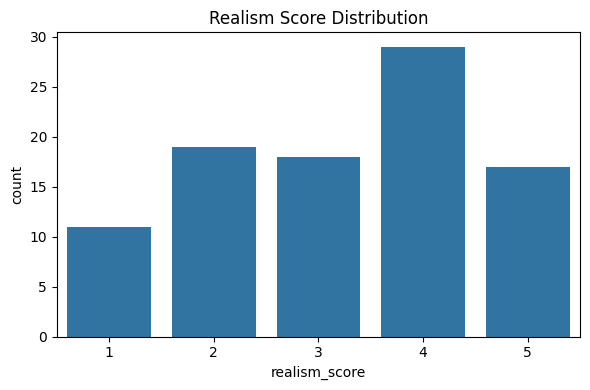

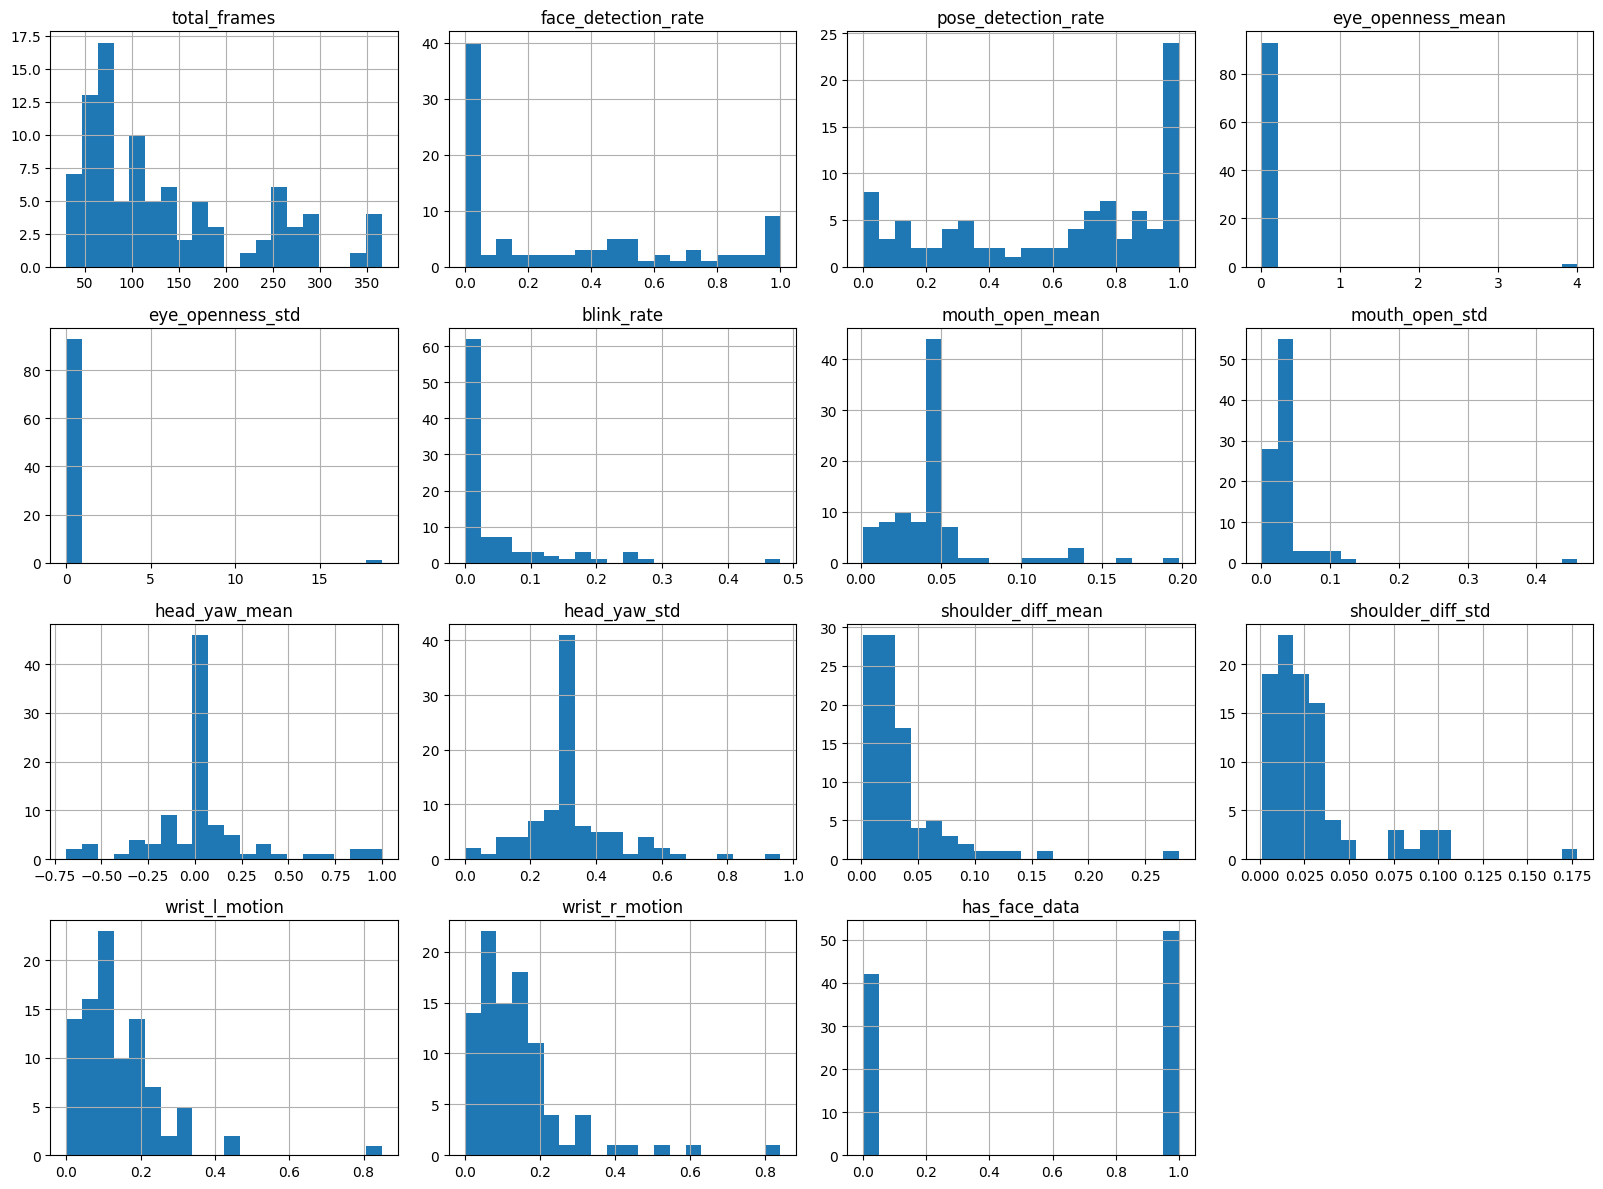

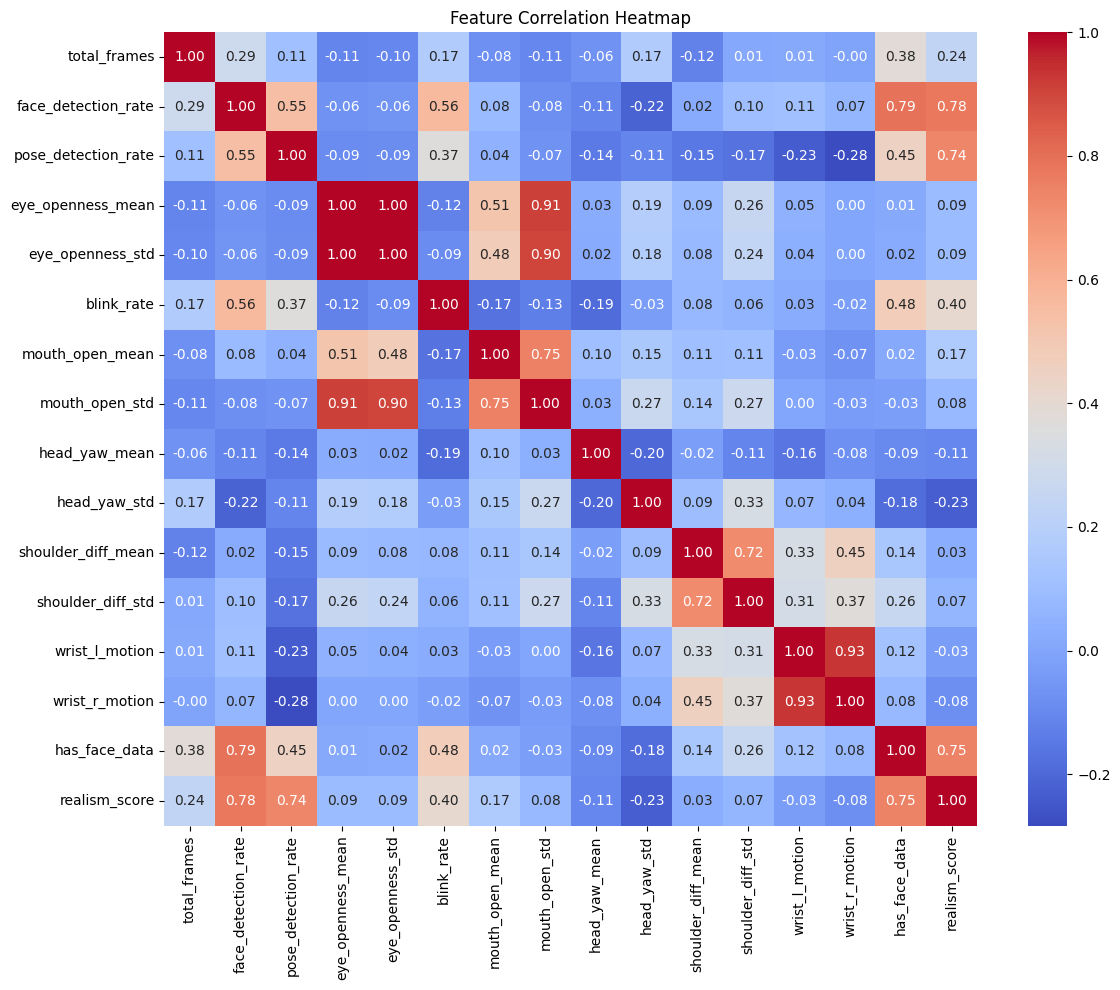


Avg realism_score by source:
source
WOW          1.800000
wearecult    2.333333
pixabay      2.676471
ashish       3.166667
SUGAR        3.400000
Physics      3.500000
mCaffeine    3.555556
Trakin       3.750000
Dushyant     4.000000
Technical    4.000000
Flying       4.500000
Mamaearth    4.555556
Name: realism_score, dtype: float64

Avg face_detection_rate by source:
source
wearecult    0.000000
pixabay      0.135225
WOW          0.214874
Technical    0.249012
ashish       0.305529
Trakin       0.375360
Dushyant     0.392117
Physics      0.480498
Mamaearth    0.503637
mCaffeine    0.510000
SUGAR        0.546913
Flying       0.752570
Name: face_detection_rate, dtype: float64

Feature correlation with realism_score (sorted):
face_detection_rate    0.779031
has_face_data          0.747390
pose_detection_rate    0.735833
blink_rate             0.403831
total_frames           0.237556
mouth_open_mean        0.165131
eye_openness_std       0.090114
eye_openness_mean      0.088699
mouth_op

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_train_ready.csv")

# ---- 1. Basic shape and info ----
print("Shape:", df.shape)
print(df.info())
print(df.describe())

# ---- 2. Missing values check ----
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ---- 3. Label distribution (realism_score) ----
print("\nLabel distribution:")
print(df["realism_score"].value_counts().sort_index())

plt.figure(figsize=(6,4))
sns.countplot(x="realism_score", data=df)
plt.title("Realism Score Distribution")
plt.tight_layout()
plt.savefig("D:/UGC_Project/pilot_features/eda_label_distribution.png")
plt.show()

# ---- 4. Feature distributions ----
feature_cols = [c for c in df.columns if c not in ["video_id", "realism_score"]]

df[feature_cols].hist(figsize=(16, 12), bins=20)
plt.tight_layout()
plt.savefig("D:/UGC_Project/pilot_features/eda_feature_histograms.png")
plt.show()

# ---- 5. Correlation heatmap ----
plt.figure(figsize=(12, 10))
sns.heatmap(df[feature_cols + ["realism_score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("D:/UGC_Project/pilot_features/eda_correlation_heatmap.png")
plt.show()

# ---- 6. Source-wise breakdown ----
df["source"] = df["video_id"].str.extract(r'^([a-zA-Z_ ]+?)_')

print("\nAvg realism_score by source:")
print(df.groupby("source")["realism_score"].mean().sort_values())

print("\nAvg face_detection_rate by source:")
print(df.groupby("source")["face_detection_rate"].mean().sort_values())

# ---- 7. Correlation of each feature with the label specifically (sorted) ----
print("\nFeature correlation with realism_score (sorted):")
print(df[feature_cols + ["realism_score"]].corr()["realism_score"].drop("realism_score").sort_values(ascending=False))

## 7. Final EDA on Merged Dataset

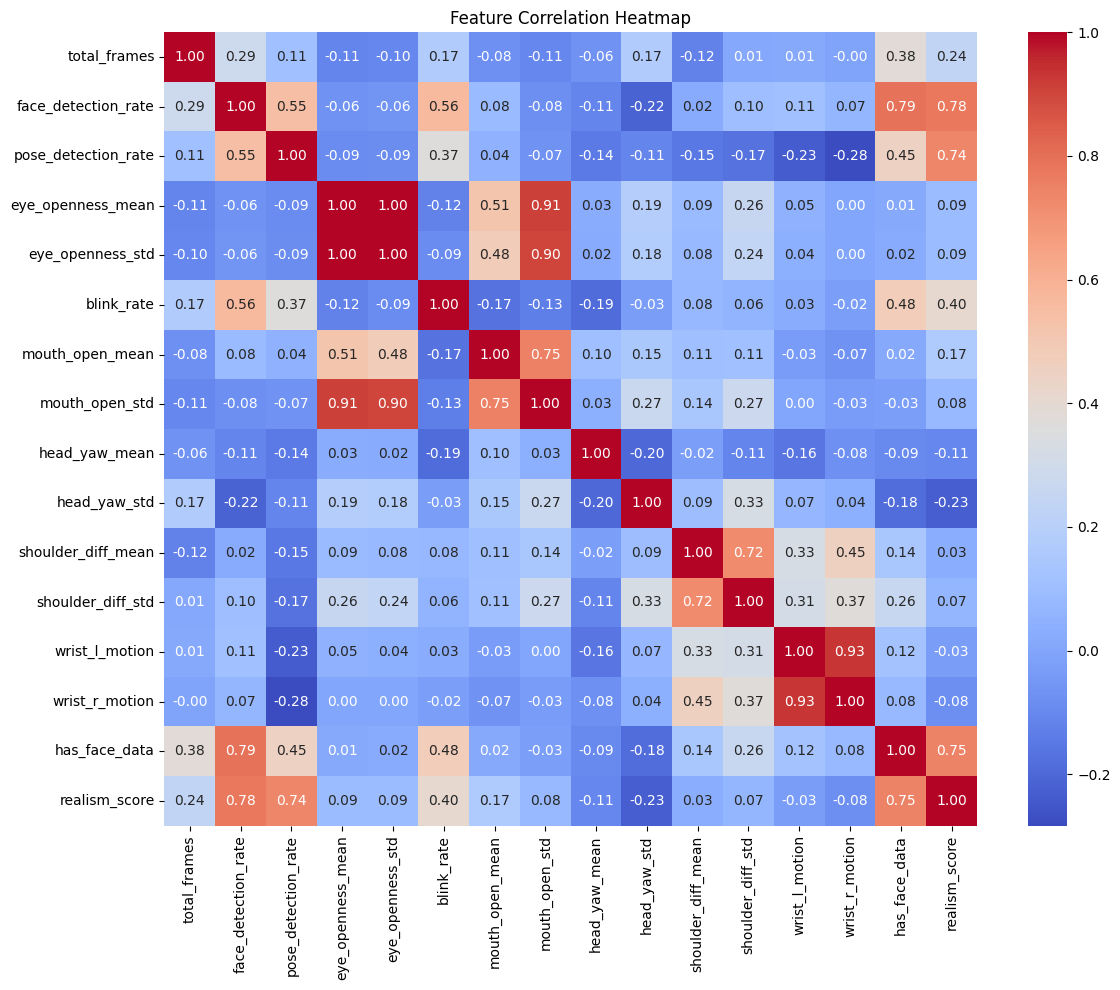

In [49]:
# ---- 5. Correlation heatmap ----
plt.figure(figsize=(12, 10))
sns.heatmap(df[feature_cols + ["realism_score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("D:/UGC_Project/pilot_features/eda_correlation_heatmap.png")
plt.show()


In [1]:
# Clean label 
import pandas as pd
import re

# Load your feature CSV and the cleaned labels
features = pd.read_csv("D:/UGC_Project/pilot_features/pilot_statistical_features_final.csv")
labels = pd.read_csv("D:/UGC_Project/labels/pilot_labels_clean.csv")

# Normalize video_id in both: lowercase + replace spaces/underscores consistently
def normalize_id(vid):
    vid = str(vid).lower()
    vid = re.sub(r'[\s_]+', '_', vid)   # collapse spaces/underscores into single underscore
    return vid.strip()

features["video_id_norm"] = features["video_id"].apply(normalize_id)
labels["video_id_norm"] = labels["video_id"].apply(normalize_id)

# Merge on normalized ID
merged = pd.merge(features, labels[["video_id_norm", "realism_score"]], on="video_id_norm", how="inner")

print(f"Features rows: {len(features)}")
print(f"Labels rows: {len(labels)}")
print(f"Matched after merge: {len(merged)}")

# Check for any unmatched videos
unmatched = set(features["video_id_norm"]) - set(labels["video_id_norm"])
print(f"\nUnmatched video count: {len(unmatched)}")
if unmatched:
    print("Sample unmatched:", list(unmatched)[:5])

# Drop the helper column and save final training-ready dataset
merged = merged.drop(columns=["video_id_norm"])
merged.to_csv("D:/UGC_Project/pilot_features/pilot_train_ready.csv", index=False)
print(f"\nSaved training-ready file with {len(merged)} rows and {merged.shape[1]} columns")

Features rows: 98
Labels rows: 100
Matched after merge: 94

Unmatched video count: 4
Sample unmatched: ['wow_skin_science_india_ejsqpf_tz3g', 'wow_skin_science_india_2znxenfq8ms', 'wearecult_ktjzgq9kuf4', 'pixabay_global_218506']

Saved training-ready file with 94 rows and 17 columns


## 8. Debugging Remaining Unmatched Labels

In [2]:
# Check what labels DID contain for similar-looking names
similar_check = labels[labels["video_id_norm"].str.contains("wow_skin|wearecult|pixabay_global_218", na=False, regex=True)]
print(similar_check[["video_id", "video_id_norm"]])

                              video_id                       video_id_norm
86               wearecult_2gGAxoAX-5I               wearecult_2ggaxoax-5i
87               wearecult_6etU_bn_exs               wearecult_6etu_bn_exs
88               wearecult_hO7ktCF0T7U               wearecult_ho7ktcf0t7u
89  WOW_Skin_Science_India_2OtSxNLpiTo  wow_skin_science_india_2otsxnlpito
90  WOW_Skin_Science_India_314allEv6I4  wow_skin_science_india_314allev6i4
91  WOW_Skin_Science_India_NhxOGhwHcMM  wow_skin_science_india_nhxoghwhcmm
92  WOW_Skin_Science_India_pUliq3Butm4  wow_skin_science_india_puliq3butm4
93  WOW_Skin_Science_India_Xq7AHh6Qm6M  wow_skin_science_india_xq7ahh6qm6m


## 9. XGBoost Training & Evaluation

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the training-ready dataset
df = pd.read_csv("D:/UGC_Project/pilot_features/pilot_train_ready.csv")

# Features (X) - drop identifier and target columns
feature_cols = [
    "total_frames", "face_detection_rate", "pose_detection_rate",
    "eye_openness_mean", "eye_openness_std", "blink_rate",
    "mouth_open_mean", "mouth_open_std", "head_yaw_mean", "head_yaw_std",
    "shoulder_diff_mean", "shoulder_diff_std", "wrist_l_motion", "wrist_r_motion",
    "has_face_data"
]

X = df[feature_cols]
y = df["realism_score"]

# 80/20 train-test split (as decided earlier)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

# Train XGBoost regressor
model = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"\nMAE (Mean Absolute Error): {mae:.3f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.3f}")
print(f"R² Score: {r2:.3f}")

# Show feature importance
importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nFeature Importance:")
print(importance)

C:\Users\Anurag\anaconda3\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Train size: 75 | Test size: 19

MAE (Mean Absolute Error): 0.628
RMSE (Root Mean Squared Error): 0.795
R² Score: 0.630

Feature Importance:
                feature  importance
2   pose_detection_rate    0.578783
1   face_detection_rate    0.189799
7        mouth_open_std    0.126846
8         head_yaw_mean    0.023066
6       mouth_open_mean    0.013545
3     eye_openness_mean    0.011802
12       wrist_l_motion    0.011717
0          total_frames    0.010103
11    shoulder_diff_std    0.008737
13       wrist_r_motion    0.006599
4      eye_openness_std    0.006582
10   shoulder_diff_mean    0.006530
5            blink_rate    0.003213
9          head_yaw_std    0.002678
14        has_face_data    0.000000


In [4]:
# Calculate percentage of predictions within 1 point of actual score
within_1_point = (abs(y_test.values - y_pred) <= 1).mean() * 100
print(f"Predictions within ±1 point: {within_1_point:.1f}%")

Predictions within ±1 point: 84.2%


## 10. GNN Training & Evaluation

In [5]:
!pip install torch --quiet
!pip install torch_geometric --quiet

In [6]:
import torch
import torch_geometric
print("Torch version:", torch.__version__)
print("PyG version:", torch_geometric.__version__)

C:\Users\Anurag\anaconda3\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Torch version: 2.14.0+cpu
PyG version: 2.8.0.post1


In [8]:
import os
path = "D:/UGC_Project/pilot_features/raw_landmarks/ashish chanchlani vines_6w_Wy2Sb82w.pkl"
print(f"File size: {os.path.getsize(path)} bytes")

File size: 16270540 bytes


In [9]:
landmarks_dir = "D:/UGC_Project/pilot_features/raw_landmarks"
files = [f for f in os.listdir(landmarks_dir) if f.endswith(".pkl") and "_v2" not in f]
print(f"Total v1 landmark files: {len(files)}")

corrupted = []
for fname in files:
    fpath = os.path.join(landmarks_dir, fname)
    try:
        with open(fpath, "rb") as f:
            pickle.load(f)
    except Exception as e:
        corrupted.append(fname)

print(f"Corrupted files: {len(corrupted)}")
print(corrupted[:10])

Total v1 landmark files: 98
Corrupted files: 1
['ashish chanchlani vines_6w_Wy2Sb82w.pkl']


In [10]:
import pickle

# use a different, confirmed-good video
sample_id = [f for f in files if f not in corrupted][0]
print(f"Testing: {sample_id}")

with open(os.path.join(landmarks_dir, sample_id), "rb") as f:
    sample_landmarks = pickle.load(f)

print(f"Total frames: {len(sample_landmarks)}")
print(f"Frame 0 keys: {sample_landmarks[0].keys()}")
print(f"Face landmarks in frame 0: {'present' if sample_landmarks[0]['face'] is not None else 'None'}")
print(f"Pose landmarks in frame 0: {'present' if sample_landmarks[0]['pose'] is not None else 'None'}")

if sample_landmarks[0]['face'] is not None:
    print(f"Number of face points: {len(sample_landmarks[0]['face'])}")
if sample_landmarks[0]['pose'] is not None:
    print(f"Number of pose points: {len(sample_landmarks[0]['pose'])}")

Testing: ashish chanchlani vines_HjzIiSjqiC0.pkl
Total frames: 139
Frame 0 keys: dict_keys(['face', 'pose'])
Face landmarks in frame 0: None
Pose landmarks in frame 0: None


In [11]:
# find first frame with actual face and pose data
for i, frame_data in enumerate(sample_landmarks):
    if frame_data['face'] is not None and frame_data['pose'] is not None:
        print(f"Frame {i} has both face and pose detected")
        print(f"Number of face points: {len(frame_data['face'])}")
        print(f"Number of pose points: {len(frame_data['pose'])}")
        print(f"Sample face point: {frame_data['face'][0]}")
        print(f"Sample pose point: {frame_data['pose'][0]}")
        break

Frame 11 has both face and pose detected
Number of face points: 478
Number of pose points: 33
Sample face point: (0.3403736650943756, 0.470750629901886, -0.02953404374420643)
Sample pose point: (0.7653889656066895, 0.3115619421005249, -0.12577173113822937)


In [12]:
# Average landmarks across all frames where both face and pose were detected
import numpy as np

def get_averaged_landmarks(landmark_sequence):
    face_frames = [f['face'] for f in landmark_sequence if f['face'] is not None]
    pose_frames = [f['pose'] for f in landmark_sequence if f['pose'] is not None]

    avg_face = np.mean(np.array(face_frames), axis=0) if face_frames else None
    avg_pose = np.mean(np.array(pose_frames), axis=0) if pose_frames else None

    return avg_face, avg_pose

avg_face, avg_pose = get_averaged_landmarks(sample_landmarks)
print(f"Averaged face shape: {avg_face.shape if avg_face is not None else 'None'}")
print(f"Averaged pose shape: {avg_pose.shape if avg_pose is not None else 'None'}")

Averaged face shape: (478, 3)
Averaged pose shape: (33, 3)


In [15]:
# Standard MediaPipe Pose skeletal connections (33 landmarks)
POSE_CONNECTIONS = [
    (0,1),(1,2),(2,3),(3,7),(0,4),(4,5),(5,6),(6,8),
    (9,10),(11,12),(11,13),(13,15),(15,17),(15,19),(15,21),(17,19),
    (12,14),(14,16),(16,18),(16,20),(16,22),(18,20),
    (11,23),(12,24),(23,24),(23,25),(24,26),(25,27),(26,28),
    (27,29),(28,30),(29,31),(30,32),(27,31),(28,32)
]
print(f"Pose edges: {len(POSE_CONNECTIONS)}")

Pose edges: 35


In [16]:
# Simplified face structure - key points and their logical connections
FACE_KEY_POINTS = [159, 145, 386, 374, 13, 14, 1, 234, 454]

FACE_CONNECTIONS = [
    (159,145),   # left eye top-bottom
    (386,374),   # right eye top-bottom
    (13,14),     # mouth top-bottom
    (1,234),     # nose to left cheek
    (1,454),     # nose to right cheek
    (159,1),     # left eye to nose
    (386,1),     # right eye to nose
]
print(f"Simplified face edges: {len(FACE_CONNECTIONS)}")

Simplified face edges: 7


In [17]:
import torch
from torch_geometric.data import Data

def build_graph(avg_face, avg_pose, realism_score):
    """
    Combines face (key points only) + pose landmarks into one graph.
    Nodes = landmark coordinates, Edges = skeletal/facial connections.
    """
    # Select only the key face points (not all 478) to keep graph size manageable
    face_node_coords = avg_face[FACE_KEY_POINTS] if avg_face is not None else np.zeros((len(FACE_KEY_POINTS), 3))
    pose_node_coords = avg_pose if avg_pose is not None else np.zeros((33, 3))

    # Combine into one node feature matrix (face nodes first, then pose nodes)
    all_nodes = np.vstack([face_node_coords, pose_node_coords])
    x = torch.tensor(all_nodes, dtype=torch.float)

    # Build edge index - face edges use original indices 0-8 (after remapping),
    # pose edges are offset by number of face nodes
    face_idx_map = {orig_idx: new_idx for new_idx, orig_idx in enumerate(FACE_KEY_POINTS)}
    face_edges = [(face_idx_map[a], face_idx_map[b]) for a, b in FACE_CONNECTIONS]

    pose_offset = len(FACE_KEY_POINTS)
    pose_edges = [(a + pose_offset, b + pose_offset) for a, b in POSE_CONNECTIONS]

    all_edges = face_edges + pose_edges
    edge_index = torch.tensor(all_edges, dtype=torch.long).t().contiguous()

    # Target label
    y = torch.tensor([realism_score], dtype=torch.float)

    return Data(x=x, edge_index=edge_index, y=y)

# Test on our sample video
sample_graph = build_graph(avg_face, avg_pose, realism_score=4)
print(sample_graph)
print(f"Node feature shape: {sample_graph.x.shape}")
print(f"Edge index shape: {sample_graph.edge_index.shape}")

Data(x=[42, 3], edge_index=[2, 42], y=[1])
Node feature shape: torch.Size([42, 3])
Edge index shape: torch.Size([2, 42])


In [18]:
from tqdm import tqdm

graph_dataset = []
skipped = 0

for _, row in tqdm(merged.iterrows(), total=len(merged), desc="Building graphs"):
    video_id = row["video_id"]
    realism_score = row["realism_score"]

    pkl_path = os.path.join(landmarks_dir, f"{video_id}.pkl")

    # try matching with original naming (spaces) since merged df may have normalized names
    if not os.path.exists(pkl_path):
        # try finding the actual file with matching normalized name
        matches = [f for f in files if f.replace(" ", "_").replace(".pkl","").lower() == video_id.lower()]
        if matches:
            pkl_path = os.path.join(landmarks_dir, matches[0])
        else:
            skipped += 1
            continue

    try:
        with open(pkl_path, "rb") as f:
            landmark_seq = pickle.load(f)
    except Exception:
        skipped += 1
        continue

    avg_face, avg_pose = get_averaged_landmarks(landmark_seq)

    if avg_face is None and avg_pose is None:
        skipped += 1
        continue

    graph = build_graph(avg_face, avg_pose, realism_score)
    graph_dataset.append(graph)

print(f"\nTotal graphs built: {len(graph_dataset)}")
print(f"Skipped: {skipped}")

Building graphs: 100%|█████████████████████████████████████████████████████████████████| 94/94 [00:03<00:00, 30.29it/s]


Total graphs built: 89
Skipped: 5


In [19]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split

# Split graphs into train/test (80/20, same as XGBoost)
train_graphs, test_graphs = train_test_split(graph_dataset, test_size=0.2, random_state=42)

print(f"Train graphs: {len(train_graphs)}")
print(f"Test graphs: {len(test_graphs)}")

train_loader = DataLoader(train_graphs, batch_size=8, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=8, shuffle=False)

# Define a simple GNN model
class RealismGNN(nn.Module):
    def __init__(self, in_channels=3, hidden_channels=32):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.fc = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)   # aggregate node features into one graph-level vector
        x = self.fc(x)
        return x

model_gnn = RealismGNN()
print(model_gnn)

Train graphs: 71
Test graphs: 18
RealismGNN(
  (conv1): GCNConv(3, 32)
  (conv2): GCNConv(32, 32)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [20]:
import torch.optim as optim

optimizer = optim.Adam(model_gnn.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

EPOCHS = 100

for epoch in range(EPOCHS):
    model_gnn.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_gnn(batch.x, batch.edge_index, batch.batch)
        loss = loss_fn(out.squeeze(), batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 20 == 0:
        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1}/{EPOCHS} - Train Loss: {avg_loss:.4f}")

print("\nTraining complete")

Epoch 20/100 - Train Loss: 1.1442
Epoch 40/100 - Train Loss: 0.8518
Epoch 60/100 - Train Loss: 0.7292
Epoch 80/100 - Train Loss: 0.6965
Epoch 100/100 - Train Loss: 0.6578

Training complete


In [21]:
model_gnn.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_loader:
        out = model_gnn(batch.x, batch.edge_index, batch.batch)
        all_preds.extend(out.squeeze().tolist())
        all_targets.extend(batch.y.tolist())

# handle case where last batch has only 1 sample (squeeze issue)
if isinstance(all_preds[0], float) == False:
    all_preds = [p for sublist in all_preds for p in (sublist if isinstance(sublist, list) else [sublist])]

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

mae = mean_absolute_error(all_targets, all_preds)
rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
r2 = r2_score(all_targets, all_preds)

print(f"GNN Test MAE: {mae:.3f}")
print(f"GNN Test RMSE: {rmse:.3f}")
print(f"GNN Test R²: {r2:.3f}")

within_1_point = (abs(all_targets - all_preds) <= 1).mean() * 100
print(f"Predictions within ±1 point: {within_1_point:.1f}%")

GNN Test MAE: 0.727
GNN Test RMSE: 0.880
GNN Test R²: 0.038
Predictions within ±1 point: 66.7%


In [1]:
import pandas as pd

results_table = pd.DataFrame({
    "Model": ["XGBoost (baseline)", "Standard GNN (primary)"],
    "MAE": [0.628, 0.727],
    "RMSE": [0.795, 0.880],
    "R² Score": [0.630, 0.038],
    "Within ±1 Point": ["84.2%", "66.7%"],
    "Verdict": ["Best at this scale", "Needs more data"]
})

results_table

,Model,MAE,RMSE,R² Score,Within ±1 Point,Verdict
0,XGBoost (baseline),0.628,0.795,0.630,84.2%,Best at this scale
1,Standard GNN (primary),0.727,0.880,0.038,66.7%,Needs more data
